In [1]:
import numpy as np
import pandas as pd

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report

In [6]:
import  seaborn as sns

In [27]:
df= pd.read_csv("data_A.csv")

In [28]:
df.head()

,Unnamed: 0,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0,0xa658,CUS_0x936d,March,Alistair Barrs,8466,703-48-3482,_______,100433.58,8074.465000,...,Good,1023.93,33.471395,20 Years and 5 Months,No,100.163466,758.0704866746678,Low_spent_Medium_value_payments,229.21254743638283,Standard
1,1,0x6739,CUS_0x9a29,August,Phila,25,339-28-0072,Developer,33119.82,3024.985000,...,Bad,2545.0,33.810567,14 Years and 8 Months,Yes,111.422702,NaN,Low_spent_Small_value_payments,370.6074980582689,Poor
2,2,0xdcf5,CUS_0x12a9,April,Driverb,44,583-20-9758,_______,44822.21,3555.184167,...,Good,730.64,31.145739,23 Years and 10 Months,NM,135.044286,256.4742969677053,Low_spent_Medium_value_payments,243.99983412342044,Standard
3,3,0x14453,CUS_0x3bad,June,Prasadc,29,510-25-2095,Musician,142081.48,11771.123333,...,Standard,932.32,28.409526,27 Years and 0 Months,No,180.616478,423.96126196668365,Low_spent_Small_value_payments,862.534593039876,Standard
4,4,0x1198e,CUS_0xa3e1,January,Poornimai,45,943-92-4350,Scientist,19267.27_,1374.605833,...,Bad,3777.55,28.373426,10 Years and 3 Months,Yes,78.954825,133.56850235207634,Low_spent_Small_value_payments,214.93725572483646,Poor


<Axes: xlabel='Credit_Score', ylabel='count'>

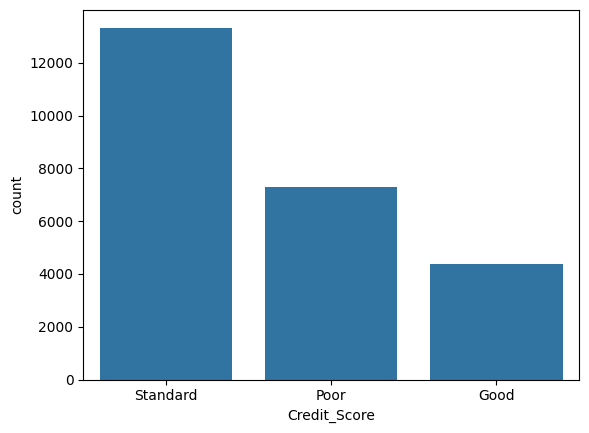

In [29]:
sns.countplot(df, x= "Credit_Score")

In [30]:
df.describe()

,Unnamed: 0,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Delay_from_due_date,Num_Credit_Inquiries,Credit_Utilization_Ratio,Total_EMI_per_month
count,25000.000000,21417.000000,25000.000000,25000.000000,25000.000000,25000.000000,24494.000000,25000.000000,25000.000000
mean,12499.500000,4215.671131,17.235440,22.143080,71.214040,21.192000,28.149669,32.295884,1406.139718
std,7217.022701,3187.623134,118.307474,127.701822,463.669065,14.887254,194.452923,5.090592,8242.321932
min,0.000000,303.645417,-1.000000,0.000000,1.000000,-5.000000,0.000000,20.172942,0.000000
25%,6249.750000,1634.720833,4.000000,4.000000,8.000000,10.000000,3.000000,28.104589,30.750519
50%,12499.500000,3111.437500,6.000000,5.000000,13.000000,18.000000,6.000000,32.288376,70.523826
75%,18749.250000,5986.647500,7.000000,7.000000,20.000000,28.000000,9.000000,36.480066,163.598381
max,24999.000000,15167.180000,1798.000000,1499.000000,5775.000000,67.000000,2597.000000,48.489852,82236.000000


In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Unnamed: 0                25000 non-null  int64  
 1   ID                        25000 non-null  object 
 2   Customer_ID               25000 non-null  object 
 3   Month                     25000 non-null  object 
 4   Name                      22440 non-null  object 
 5   Age                       25000 non-null  object 
 6   SSN                       25000 non-null  object 
 7   Occupation                25000 non-null  object 
 8   Annual_Income             25000 non-null  object 
 9   Monthly_Inhand_Salary     21417 non-null  float64
 10  Num_Bank_Accounts         25000 non-null  int64  
 11  Num_Credit_Card           25000 non-null  int64  
 12  Interest_Rate             25000 non-null  int64  
 13  Num_of_Loan               25000 non-null  object 
 14  Type_o

byk tipe ga sesuai

In [10]:
df

,Unnamed: 0,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0,0xa658,CUS_0x936d,March,Alistair Barrs,8466,703-48-3482,_______,100433.58,8074.465000,...,Good,1023.93,33.471395,20 Years and 5 Months,No,100.163466,758.0704866746678,Low_spent_Medium_value_payments,229.21254743638283,Standard
1,1,0x6739,CUS_0x9a29,August,Phila,25,339-28-0072,Developer,33119.82,3024.985000,...,Bad,2545.0,33.810567,14 Years and 8 Months,Yes,111.422702,NaN,Low_spent_Small_value_payments,370.6074980582689,Poor
2,2,0xdcf5,CUS_0x12a9,April,Driverb,44,583-20-9758,_______,44822.21,3555.184167,...,Good,730.64,31.145739,23 Years and 10 Months,NM,135.044286,256.4742969677053,Low_spent_Medium_value_payments,243.99983412342044,Standard
3,3,0x14453,CUS_0x3bad,June,Prasadc,29,510-25-2095,Musician,142081.48,11771.123333,...,Standard,932.32,28.409526,27 Years and 0 Months,No,180.616478,423.96126196668365,Low_spent_Small_value_payments,862.534593039876,Standard
4,4,0x1198e,CUS_0xa3e1,January,Poornimai,45,943-92-4350,Scientist,19267.27_,1374.605833,...,Bad,3777.55,28.373426,10 Years and 3 Months,Yes,78.954825,133.56850235207634,Low_spent_Small_value_payments,214.93725572483646,Poor
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24995,24995,0x106bb,CUS_0x3854,June,Kimt,21,774-91-6471,Manager,40100.45,3280.704167,...,Good,821.74,31.398811,NaN,No,0.000000,119.11335358096089,High_spent_Small_value_payments,468.9570630857058,Good
24996,24996,0x166ec,CUS_0xc80,July,Chris Reesel,31,610-12-1484,Musician,48706.1_,4052.841667,...,Standard,1083.76,29.566754,17 Years and 4 Months,Yes,107.152558,156.67313580334772,High_spent_Medium_value_payments,391.4584731707637,Standard
24997,24997,0x7e21,CUS_0x16c4,April,Marjag,17,365-26-7399,_______,8473.795,512.149583,...,Standard,1040.14,38.176695,17 Years and 5 Months,Yes,16.798847,41.360646709309634,Low_spent_Small_value_payments,283.05546449166764,Standard
24998,24998,0x199fe,CUS_0x8a50,January,Scottu,23,742-72-0073,Developer,68281.18,5920.098333,...,_,476.18,32.675313,NaN,No,5851.000000,NaN,!@9#%8,591.976496397994,Good


In [11]:
df.columns

Index(['Unnamed: 0', 'ID', 'Customer_ID', 'Month', 'Name', 'Age', 'SSN',
       'Occupation', 'Annual_Income', 'Monthly_Inhand_Salary',
       'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan',
       'Type_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment',
       'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix',
       'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_History_Age',
       'Payment_of_Min_Amount', 'Total_EMI_per_month',
       'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance',
       'Credit_Score'],
      dtype='object')

In [32]:
for col in df:
    print(df[col].value_counts())

Unnamed: 0
0        1
1        1
2        1
3        1
4        1
        ..
24995    1
24996    1
24997    1
24998    1
24999    1
Name: count, Length: 25000, dtype: int64
ID
0xa658     1
0x6739     1
0xdcf5     1
0x14453    1
0x1198e    1
          ..
0x106bb    1
0x166ec    1
0x7e21     1
0x199fe    1
0x21ffd    1
Name: count, Length: 25000, dtype: int64
Customer_ID
CUS_0x9bbe    7
CUS_0x215f    7
CUS_0x627f    7
CUS_0x8da9    7
CUS_0x6b8     7
             ..
CUS_0xa9a8    1
CUS_0x1ff7    1
CUS_0x5ede    1
CUS_0xadc4    1
CUS_0x37f8    1
Name: count, Length: 11252, dtype: int64
Month
April       3173
July        3156
May         3151
March       3139
June        3131
August      3100
February    3087
January     3063
Name: count, dtype: int64
Name
Strupczewskid        14
Andreax              13
Jonathan Stempelr    13
Jonathan Stempelb    12
Stevex               12
                     ..
Hirschlerm            1
Susanr                1
Ilainaj               1
Karen Freifeldk       

In [33]:
df["Credit_Mix"] = df["Credit_Mix"].replace("_", np.nan)
df["Payment_Behaviour"] = df["Payment_Behaviour"].replace("!@9#%8", np.nan)
df["Payment_of_Min_Amount"] = df["Payment_of_Min_Amount"].replace("NM", np.nan)
df["Occupation"] = df["Occupation"].replace("_______", np.nan)
df["SSN"] = df["SSN"].replace("#F%$D@*&8", np.nan)

# 2. List semua kolom numerik yang terkontaminasi teks/simbol
contaminated_cols = [
    "Age",
    "Annual_Income",
    "Monthly_Inhand_Salary",
    "Num_Bank_Accounts",
    "Num_Credit_Card",
    "Interest_Rate",
    "Num_of_Loan",
    "Num_of_Delayed_Payment",
    "Changed_Credit_Limit",
    "Num_Credit_Inquiries",
    "Outstanding_Debt",
    "Credit_Utilization_Ratio",
    "Total_EMI_per_month",
    "Amount_invested_monthly",
    "Monthly_Balance",
]

# 3. Hapus karakter selain angka lalu konversi ke numerik
for col in contaminated_cols:
    df[col] = df[col].astype(str).str.replace(r"[^\d.-]", "", regex=True)
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 4. Mask nilai tidak logis / outlier
df["Age"] = df["Age"].mask((df["Age"] < 0) | (df["Age"] > 110))

df["Annual_Income"] = df["Annual_Income"].mask(
    df["Annual_Income"] < 0
)

df["Monthly_Inhand_Salary"] = df["Monthly_Inhand_Salary"].mask(
    df["Monthly_Inhand_Salary"] < 0
)

df["Num_Bank_Accounts"] = df["Num_Bank_Accounts"].mask(
    (df["Num_Bank_Accounts"] < 0) | (df["Num_Bank_Accounts"] > 20)
)

df["Num_Credit_Card"] = df["Num_Credit_Card"].mask(
    (df["Num_Credit_Card"] < 0) | (df["Num_Credit_Card"] > 20)
)

df["Interest_Rate"] = df["Interest_Rate"].mask(
    (df["Interest_Rate"] < 0) | (df["Interest_Rate"] > 100)
)

df["Num_of_Loan"] = df["Num_of_Loan"].mask(
    (df["Num_of_Loan"] < 0) | (df["Num_of_Loan"] > 20)
)

df["Delay_from_due_date"] = df["Delay_from_due_date"].mask(
    df["Delay_from_due_date"] < 0, 0
)

df["Num_of_Delayed_Payment"] = df["Num_of_Delayed_Payment"].mask(
    (df["Num_of_Delayed_Payment"] < 0) | (df["Num_of_Delayed_Payment"] > 100)
)

df["Changed_Credit_Limit"] = df["Changed_Credit_Limit"].mask(
    df["Changed_Credit_Limit"] < -100
)

df["Num_Credit_Inquiries"] = df["Num_Credit_Inquiries"].mask(
    (df["Num_Credit_Inquiries"] < 0) | (df["Num_Credit_Inquiries"] > 50)
)

df["Outstanding_Debt"] = df["Outstanding_Debt"].mask(
    df["Outstanding_Debt"] < 0
)

df["Credit_Utilization_Ratio"] = df["Credit_Utilization_Ratio"].mask(
    (df["Credit_Utilization_Ratio"] < 0) | (df["Credit_Utilization_Ratio"] > 100)
)

df["Total_EMI_per_month"] = df["Total_EMI_per_month"].mask(
    df["Total_EMI_per_month"] < 0
)

df["Amount_invested_monthly"] = df["Amount_invested_monthly"].mask(
    df["Amount_invested_monthly"] < 0
)

df["Monthly_Balance"] = df["Monthly_Balance"].mask(
    df["Monthly_Balance"] < -100000
)

In [34]:
df = df.drop(columns=['Unnamed: 0', 'ID', 'Customer_ID', 'Name', 'SSN', 'Type_of_Loan', 'Credit_History_Age'])

hapus yg high cardinality

In [35]:
for col in df:
    print(df[col].value_counts())

Month
April       3173
July        3156
May         3151
March       3139
June        3131
August      3100
February    3087
January     3063
Name: count, dtype: int64
Age
38.0    780
26.0    772
27.0    738
36.0    735
28.0    732
25.0    724
31.0    723
32.0    713
39.0    708
19.0    708
34.0    705
35.0    702
22.0    694
24.0    692
41.0    689
30.0    684
37.0    682
23.0    677
29.0    674
21.0    671
44.0    670
43.0    667
40.0    666
20.0    663
45.0    646
42.0    643
18.0    622
33.0    610
15.0    392
17.0    392
46.0    381
16.0    380
49.0    365
55.0    347
53.0    347
48.0    344
54.0    330
52.0    329
51.0    325
50.0    318
14.0    310
47.0    281
56.0    102
95.0      1
Name: count, dtype: int64
Occupation
Engineer         1650
Lawyer           1618
Architect        1613
Media_Manager    1575
Accountant       1569
Entrepreneur     1559
Developer        1556
Scientist        1553
Teacher          1552
Mechanic         1529
Journalist       1523
Doctor           1519

In [36]:
from sklearn.model_selection import train_test_split
X = df.drop("Credit_Score", axis=1)
y = df["Credit_Score"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [38]:
X_train_numeric = X_train.select_dtypes(include=['int64', 'float64'])



# Menampilkan daftar nama kolom numerik yang berhasil diambil


In [39]:
X_train_numeric.columns

Index(['Age', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts',
       'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan',
       'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit',
       'Num_Credit_Inquiries', 'Outstanding_Debt', 'Credit_Utilization_Ratio',
       'Total_EMI_per_month', 'Amount_invested_monthly', 'Monthly_Balance'],
      dtype='object')

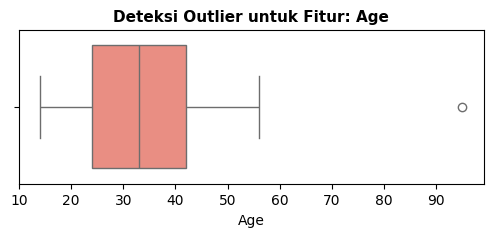

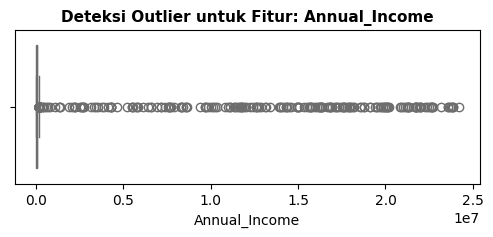

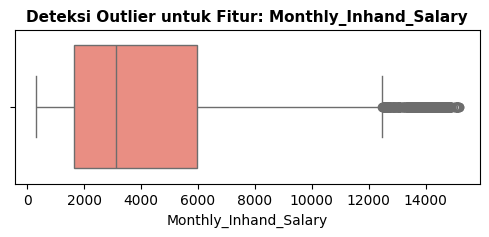

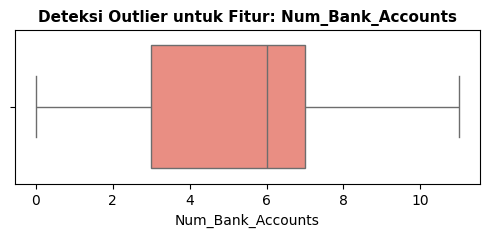

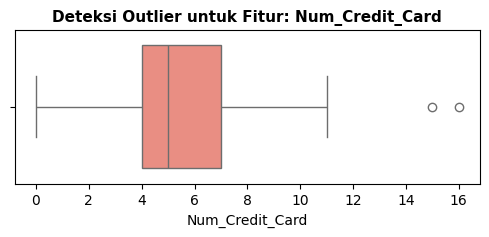

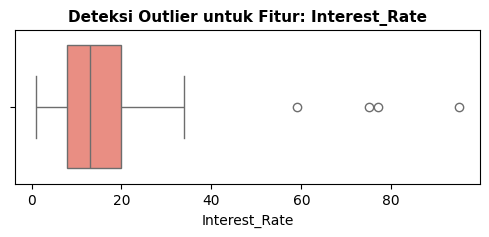

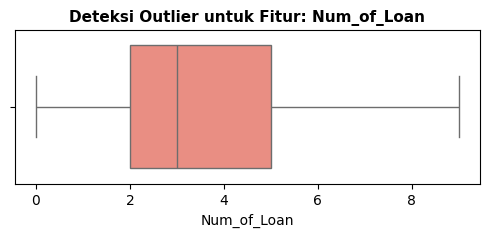

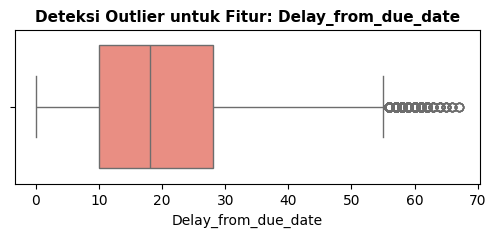

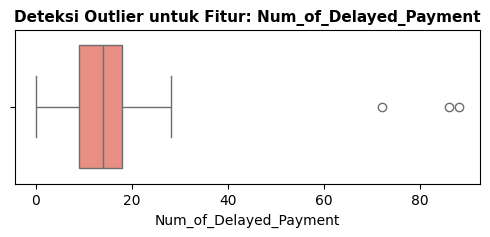

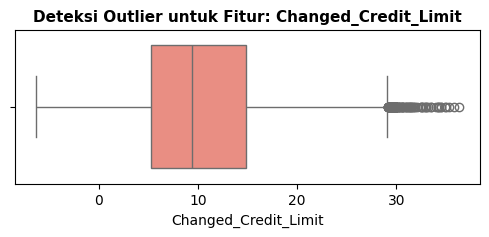

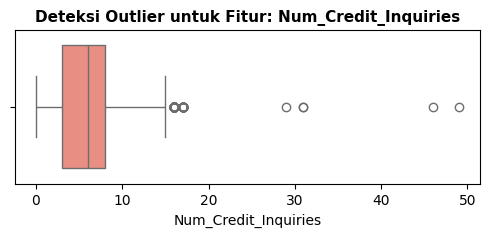

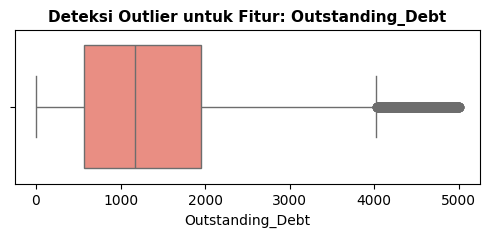

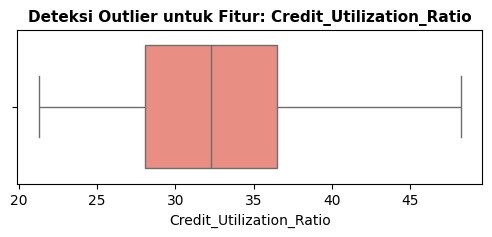

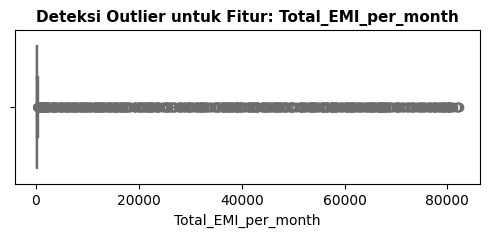

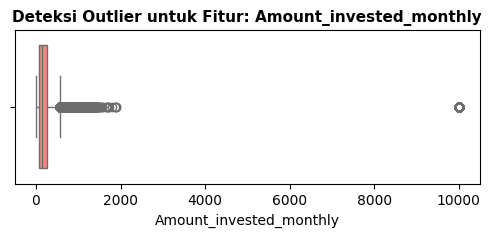

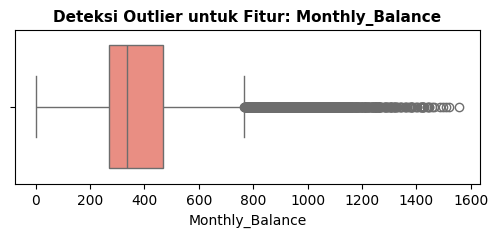

In [40]:
import seaborn as sns
import matplotlib.pyplot as plt
for col in X_train.select_dtypes(include=['int64', 'float64']).columns:
    plt.figure(figsize=(6, 2))  
    
    
    sns.boxplot(data=X_train, x=col, color='salmon')
    
    plt.title(f"Deteksi Outlier untuk Fitur: {col}", fontsize=11, fontweight='bold')
    plt.show()

In [41]:
skewed_numeric = ['Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Num_of_Delayed_Payment', 'Num_Credit_Inquiries', 'Outstanding_Debt', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Monthly_Balance']
symmetric_numeric = ['Age', 'Delay_from_due_date', 'Changed_Credit_Limit', 'Credit_Utilization_Ratio']
categorical = ['Month', 'Occupation', 'Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour']

In [42]:
preprocessor = ColumnTransformer(transformers=[
    ('num_skew', Pipeline([('imp', SimpleImputer(strategy='median')), ('scl', StandardScaler())]), skewed_numeric),
    ('num_sym', Pipeline([('imp', SimpleImputer(strategy='mean')), ('scl', StandardScaler())]), symmetric_numeric),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(handle_unknown='ignore'))]), categorical)
])

In [25]:
models_dict = {
    "Logistic_Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random_Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "Gradient_Boosting": GradientBoostingClassifier(n_estimators=100, random_state=42)
}

In [43]:
for model_name, model in models_dict.items():
    # Gabungkan preprocessor dan model
    full_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    # Lakukan Training
    full_pipeline.fit(X_train, y_train)
    
    # Lakukan Prediksi
    y_pred = full_pipeline.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    
    # Print Laporan Klasifikasi
    print(f"\n{'='*55}")
    print(f"REPORT UNTUK MODEL: {model_name}")
    print(f"{'='*55}")
    print(f"Akurasi Keseluruhan: {acc:.4f}\n")
    print(classification_report(y_test, y_pred))


REPORT UNTUK MODEL: Logistic_Regression
Akurasi Keseluruhan: 0.6394

              precision    recall  f1-score   support

        Good       0.52      0.52      0.52       856
        Poor       0.66      0.54      0.59      1501
    Standard       0.67      0.74      0.70      2643

    accuracy                           0.64      5000
   macro avg       0.61      0.60      0.60      5000
weighted avg       0.64      0.64      0.64      5000


REPORT UNTUK MODEL: Random_Forest
Akurasi Keseluruhan: 0.7216

              precision    recall  f1-score   support

        Good       0.61      0.62      0.61       856
        Poor       0.74      0.70      0.72      1501
    Standard       0.75      0.77      0.76      2643

    accuracy                           0.72      5000
   macro avg       0.70      0.70      0.70      5000
weighted avg       0.72      0.72      0.72      5000


REPORT UNTUK MODEL: Gradient_Boosting
Akurasi Keseluruhan: 0.6902

              precision    recall  f